# Notebook 03 — Exploratory Data Analysis (EDA)
**Project:** Predicting Employee Attrition at PeopleFirst Global Services
**Step:** Month 2, Weeks 6–7 — Understand patterns, distributions, and attrition drivers

---
### Objectives of this notebook
1. Understand the distribution of all key features
2. Identify how each feature relates to attrition
3. Detect outliers in numeric columns
4. Visualize attrition across departments, job roles, and demographics
5. Summarize key findings that will guide feature engineering

> **Input:** `data/processed/PeopleFirst_cleaned.csv`
> **Output:** Charts saved to `reports/`, findings summarized at the end


## 1. Import Libraries & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings, os

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

os.makedirs('../reports', exist_ok=True)

df = pd.read_csv('../data/processed/PeopleFirst_cleaned.csv')
print(f"Cleaned dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Attrition flag distribution:")
print(df['attrition_flag'].value_counts())
print(f"\nAttrition rate: {df['attrition_flag'].mean()*100:.1f}% Left")


Cleaned dataset loaded: 50,500 rows x 31 columns
Attrition flag distribution:
attrition_flag
1    31029
0    19471
Name: count, dtype: int64

Attrition rate: 61.4% Left


## 2. Target Variable Distribution

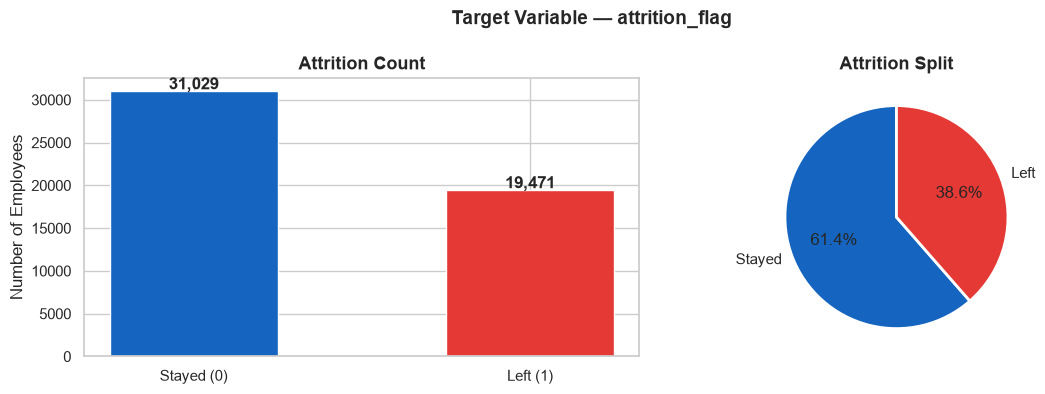

Note: 'Left' is the MAJORITY class (61.4%) — reverse of typical attrition datasets.
SMOTE will target the minority 'Stayed' class in NB04.


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))


counts = df['attrition_flag'].value_counts()
bars = axes[0].bar(['Stayed (0)', 'Left (1)'], counts.values,
                   color=['#1565C0', '#E53935'], edgecolor='white', width=0.5)
for bar, val in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
                 f'{val:,}', ha='center', fontweight='bold')
axes[0].set_title('Attrition Count')
axes[0].set_ylabel('Number of Employees')

# Pie chart
axes[1].pie(counts.values, labels=['Stayed', 'Left'],
            colors=['#1565C0', '#E53935'],
            autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Attrition Split')

plt.suptitle('Target Variable — attrition_flag', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/03_target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Note: 'Left' is the MAJORITY class (61.4%) — reverse of typical attrition datasets.")
print("SMOTE will target the minority 'Stayed' class in NB04.")


## 3. Distribution of Key Numeric Features
We look at histogram distributions of the most analytically important numeric features,
split by attrition class to see if the distributions differ between those who stayed vs left.


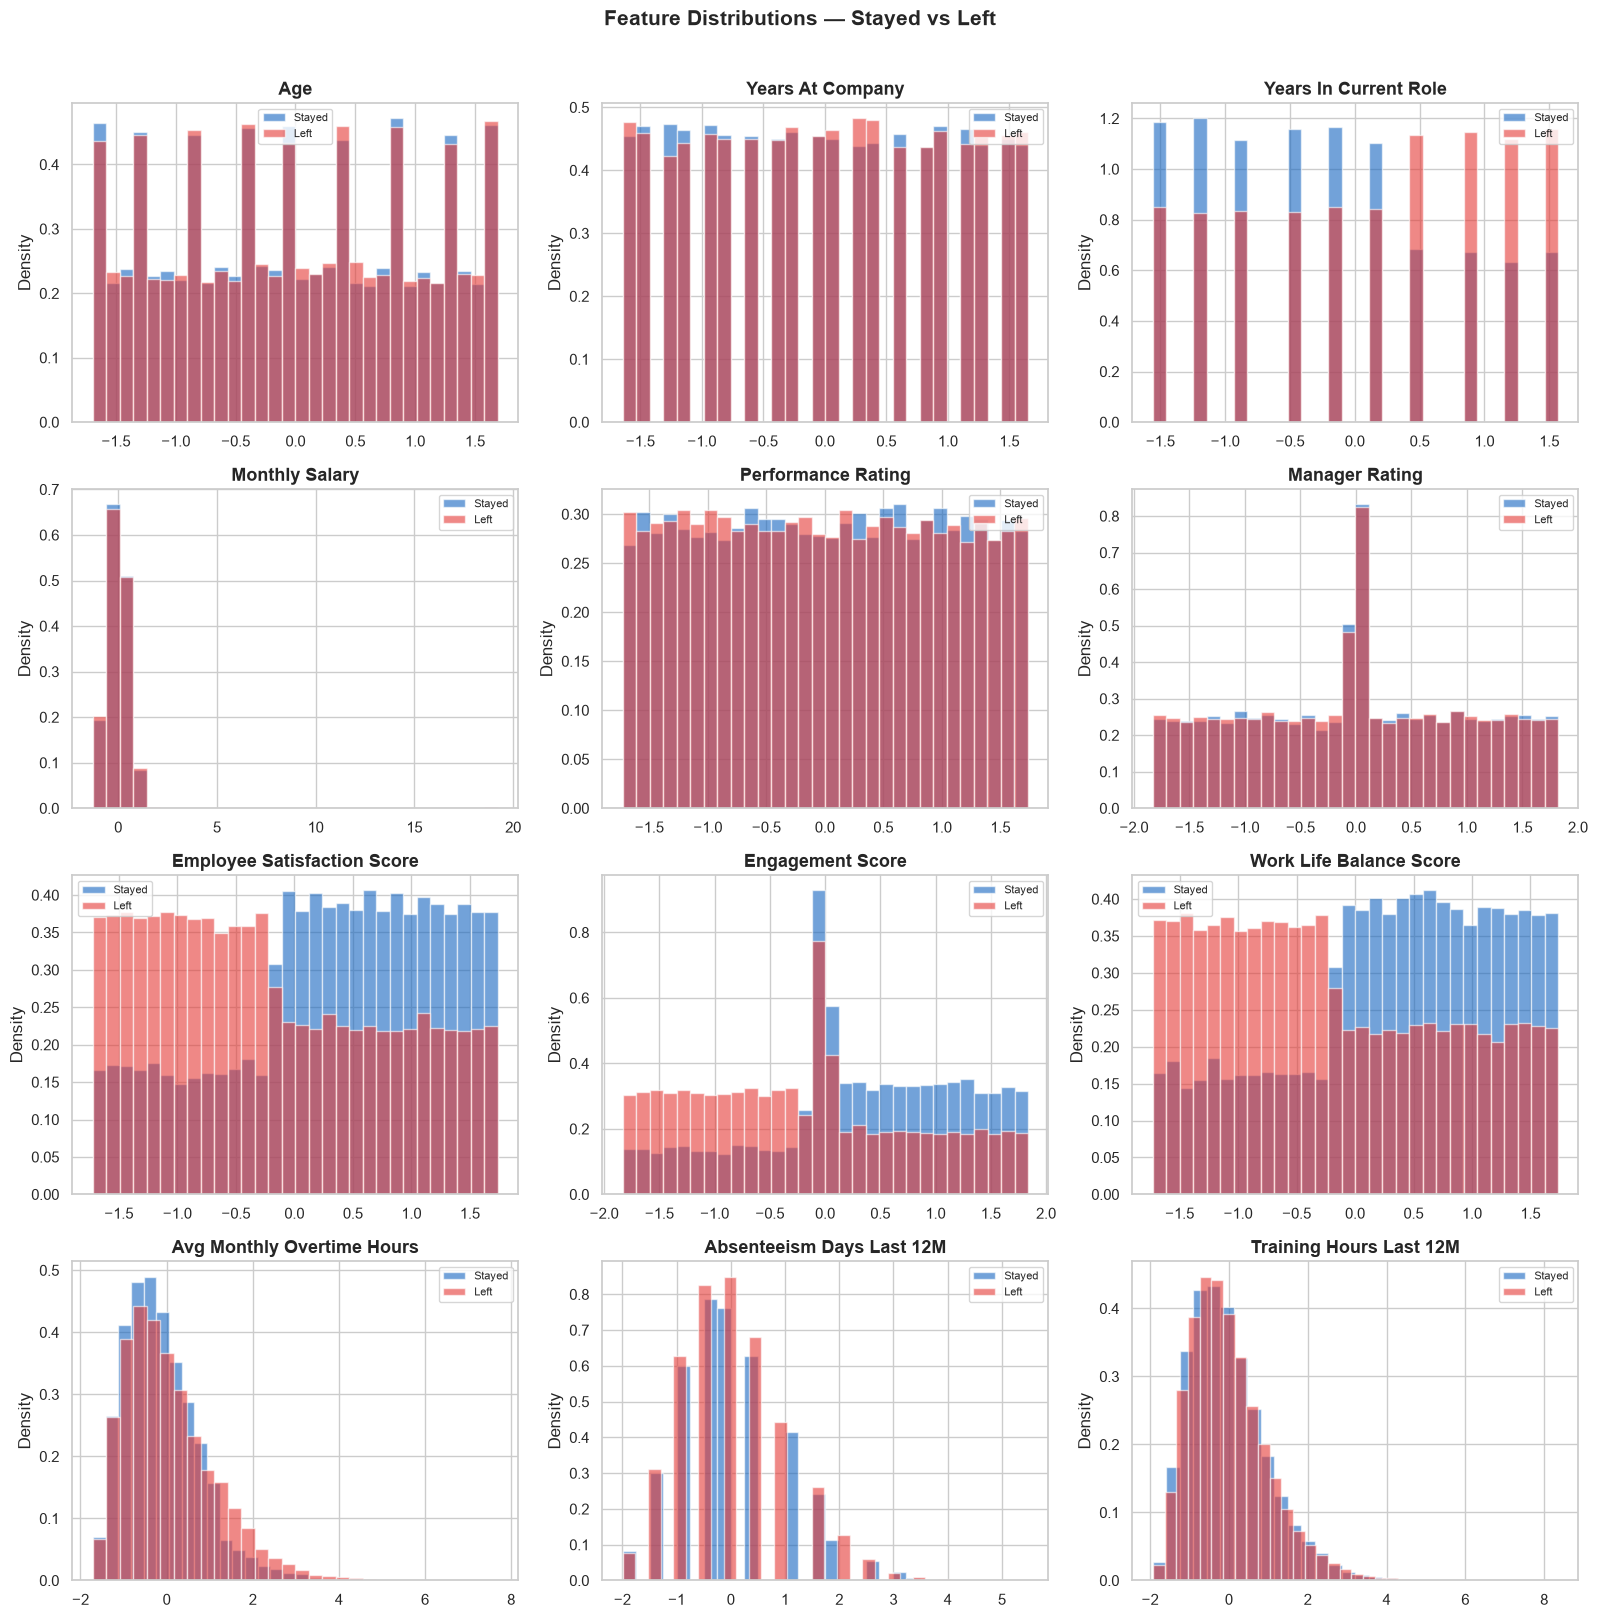

Chart saved to reports/


In [3]:
KEY_NUMERIC = [
    'age', 'years_at_company', 'years_in_current_role',
    'monthly_salary', 'performance_rating', 'manager_rating',
    'employee_satisfaction_score', 'engagement_score',
    'work_life_balance_score', 'avg_monthly_overtime_hours',
    'absenteeism_days_last_12m', 'training_hours_last_12m'
]

stayed = df[df['attrition_flag'] == 0]
left   = df[df['attrition_flag'] == 1]

fig, axes = plt.subplots(4, 3, figsize=(16, 16))
axes = axes.flatten()

for i, col in enumerate(KEY_NUMERIC):
    axes[i].hist(stayed[col], bins=30, alpha=0.6, color='#1565C0', label='Stayed', density=True)
    axes[i].hist(left[col],   bins=30, alpha=0.6, color='#E53935', label='Left',   density=True)
    axes[i].set_title(col.replace('_', ' ').title())
    axes[i].legend(fontsize=8)
    axes[i].set_ylabel('Density')

plt.suptitle('Feature Distributions — Stayed vs Left', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../reports/03_numeric_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved to reports/")


## 4. Outlier Detection — Box Plots
Box plots help us spot extreme values (outliers) that may distort model training.
We focus on compensation and workload features where outliers are most common.


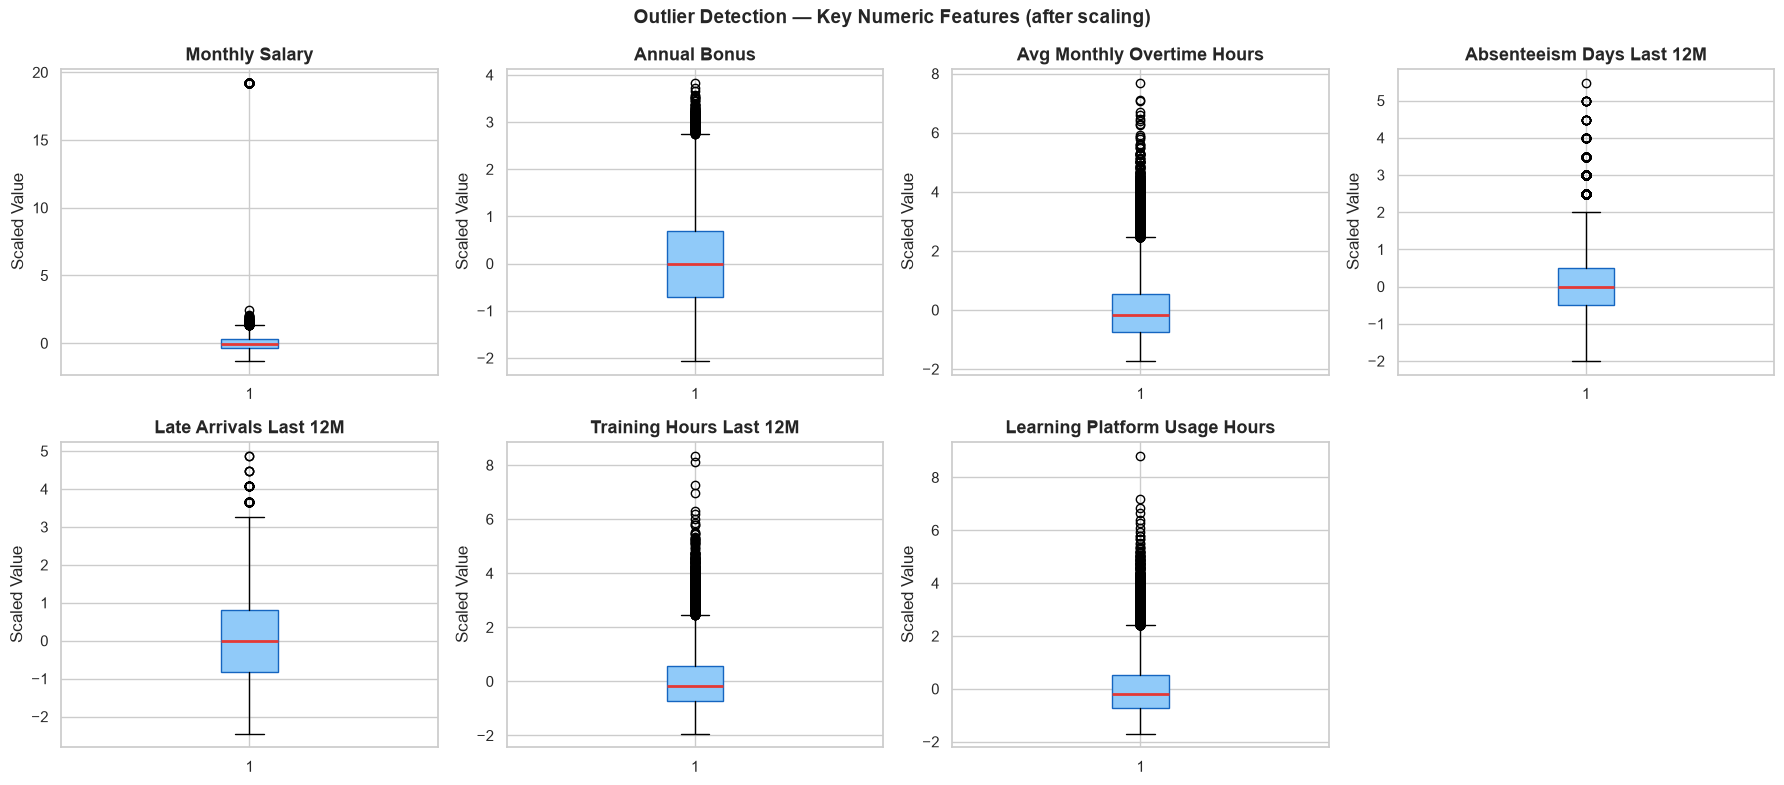

In [4]:
OUTLIER_COLS = [
    'monthly_salary', 'annual_bonus', 'avg_monthly_overtime_hours',
    'absenteeism_days_last_12m', 'late_arrivals_last_12m',
    'training_hours_last_12m', 'learning_platform_usage_hours'
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(OUTLIER_COLS):
    axes[i].boxplot(df[col].dropna(), patch_artist=True,
                    boxprops=dict(facecolor='#90CAF9', color='#1565C0'),
                    medianprops=dict(color='#E53935', linewidth=2))
    axes[i].set_title(col.replace('_', ' ').title())
    axes[i].set_ylabel('Scaled Value')

axes[-1].axis('off')  # Hide last empty subplot

plt.suptitle('Outlier Detection — Key Numeric Features (after scaling)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/03_outliers_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Attrition Rate Across Key Dimensions
We compute attrition rate (% Left) for each category of important encoded columns.
Higher bars = higher risk group.


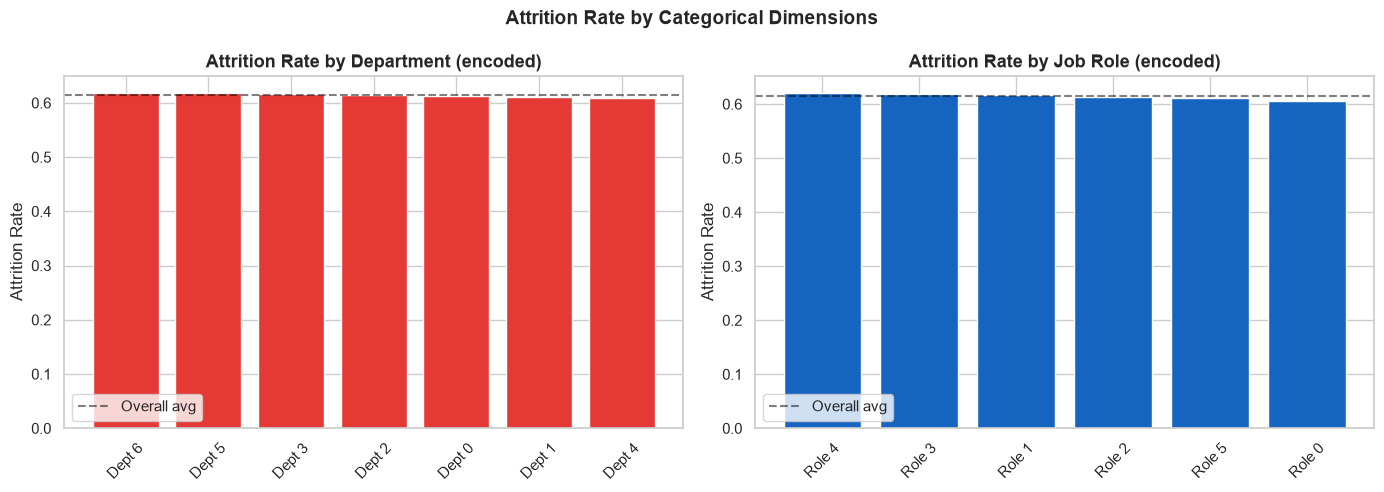

In [5]:
# Department attrition (encoded)
dept_attrition = df.groupby('department')['attrition_flag'].mean().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(range(len(dept_attrition)), dept_attrition.values, color='#E53935', edgecolor='white')
axes[0].set_xticks(range(len(dept_attrition)))
axes[0].set_xticklabels([f'Dept {int(d)}' for d in dept_attrition.index], rotation=45)
axes[0].set_title('Attrition Rate by Department (encoded)')
axes[0].set_ylabel('Attrition Rate')
axes[0].axhline(y=df['attrition_flag'].mean(), color='black', linestyle='--', alpha=0.5, label='Overall avg')
axes[0].legend()

# Job role attrition (encoded)
role_attrition = df.groupby('job_role')['attrition_flag'].mean().sort_values(ascending=False)
axes[1].bar(range(len(role_attrition)), role_attrition.values, color='#1565C0', edgecolor='white')
axes[1].set_xticks(range(len(role_attrition)))
axes[1].set_xticklabels([f'Role {int(r)}' for r in role_attrition.index], rotation=45)
axes[1].set_title('Attrition Rate by Job Role (encoded)')
axes[1].set_ylabel('Attrition Rate')
axes[1].axhline(y=df['attrition_flag'].mean(), color='black', linestyle='--', alpha=0.5, label='Overall avg')
axes[1].legend()

plt.suptitle('Attrition Rate by Categorical Dimensions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/03_categorical_attrition.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Tenure & Experience Analysis
How does time at the company and in current role affect attrition?
This is often one of the strongest predictors.


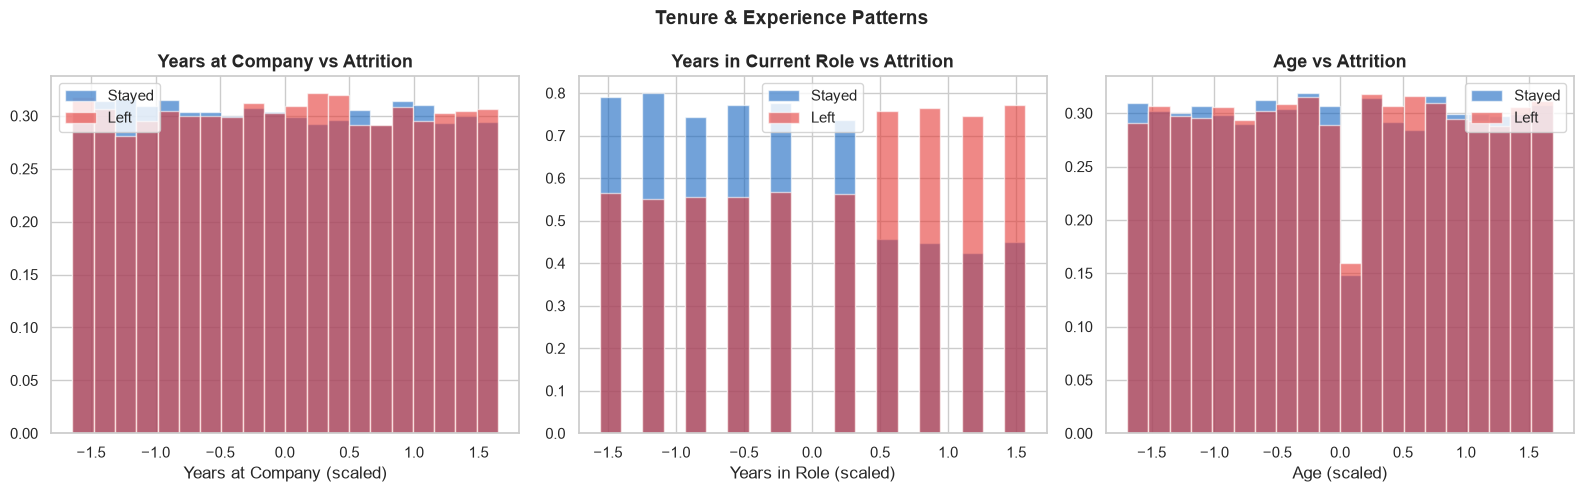

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))


axes[0].hist(stayed['years_at_company'], bins=20, alpha=0.6, color='#1565C0', label='Stayed', density=True)
axes[0].hist(left['years_at_company'],   bins=20, alpha=0.6, color='#E53935', label='Left',   density=True)
axes[0].set_title('Years at Company vs Attrition')
axes[0].set_xlabel('Years at Company (scaled)')
axes[0].legend()


axes[1].hist(stayed['years_in_current_role'], bins=20, alpha=0.6, color='#1565C0', label='Stayed', density=True)
axes[1].hist(left['years_in_current_role'],   bins=20, alpha=0.6, color='#E53935', label='Left',   density=True)
axes[1].set_title('Years in Current Role vs Attrition')
axes[1].set_xlabel('Years in Role (scaled)')
axes[1].legend()


axes[2].hist(stayed['age'], bins=20, alpha=0.6, color='#1565C0', label='Stayed', density=True)
axes[2].hist(left['age'],   bins=20, alpha=0.6, color='#E53935', label='Left',   density=True)
axes[2].set_title('Age vs Attrition')
axes[2].set_xlabel('Age (scaled)')
axes[2].legend()

plt.suptitle('Tenure & Experience Patterns', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/03_tenure_analysis.png', dpi=150, bbox_inches='tight')
plt.show()


## 7. Compensation vs Attrition

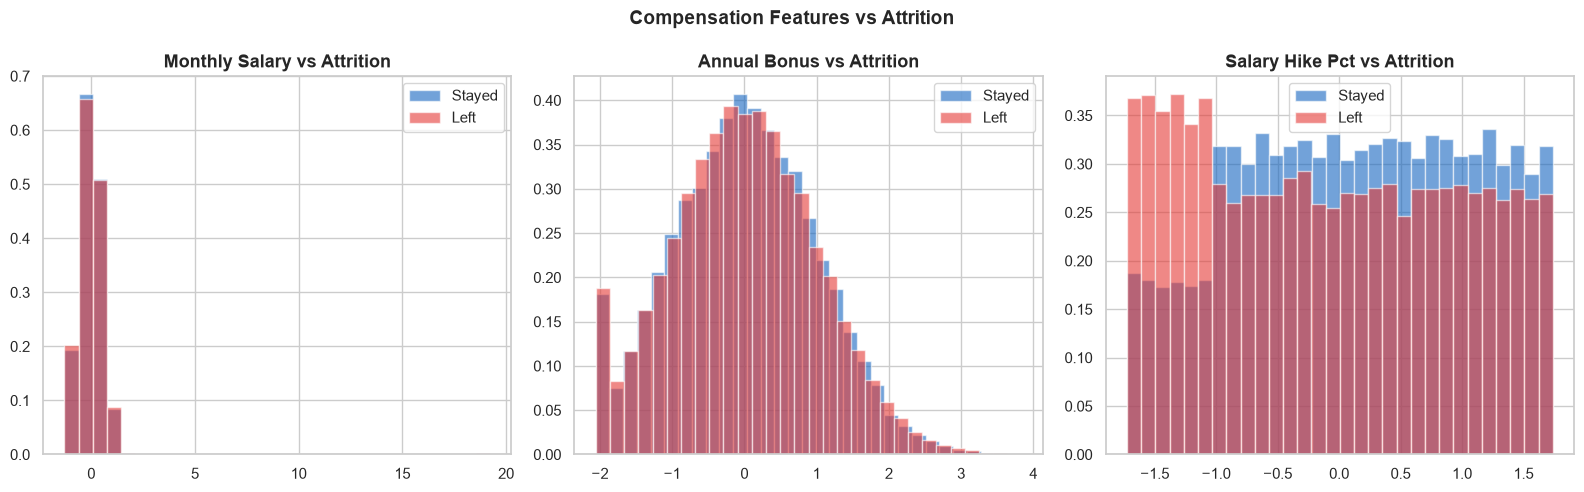

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, ['monthly_salary', 'annual_bonus', 'salary_hike_pct']):
    ax.hist(stayed[col], bins=30, alpha=0.6, color='#1565C0', label='Stayed', density=True)
    ax.hist(left[col],   bins=30, alpha=0.6, color='#E53935', label='Left',   density=True)
    ax.set_title(col.replace('_', ' ').title() + ' vs Attrition')
    ax.legend()

plt.suptitle('Compensation Features vs Attrition', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/03_compensation_attrition.png', dpi=150, bbox_inches='tight')
plt.show()


## 8. Engagement & Satisfaction vs Attrition

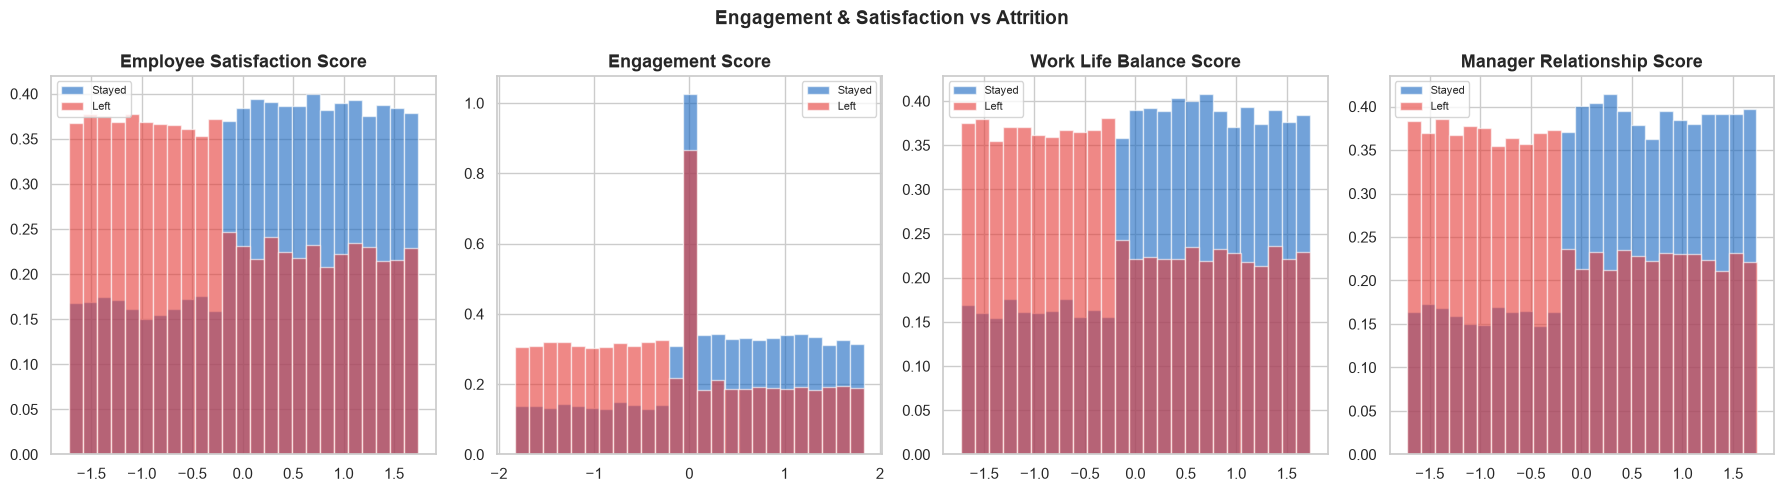

Pattern: Employees who left consistently show LOWER scores on all 4 engagement metrics.


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, col in zip(axes, ['employee_satisfaction_score', 'engagement_score',
                           'work_life_balance_score', 'manager_relationship_score']):
    ax.hist(stayed[col], bins=25, alpha=0.6, color='#1565C0', label='Stayed', density=True)
    ax.hist(left[col],   bins=25, alpha=0.6, color='#E53935', label='Left',   density=True)
    ax.set_title(col.replace('_', ' ').title())
    ax.legend(fontsize=8)

plt.suptitle('Engagement & Satisfaction vs Attrition', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/03_engagement_attrition.png', dpi=150, bbox_inches='tight')
plt.show()
print("Pattern: Employees who left consistently show LOWER scores on all 4 engagement metrics.")


## 9. Workload & Overtime vs Attrition

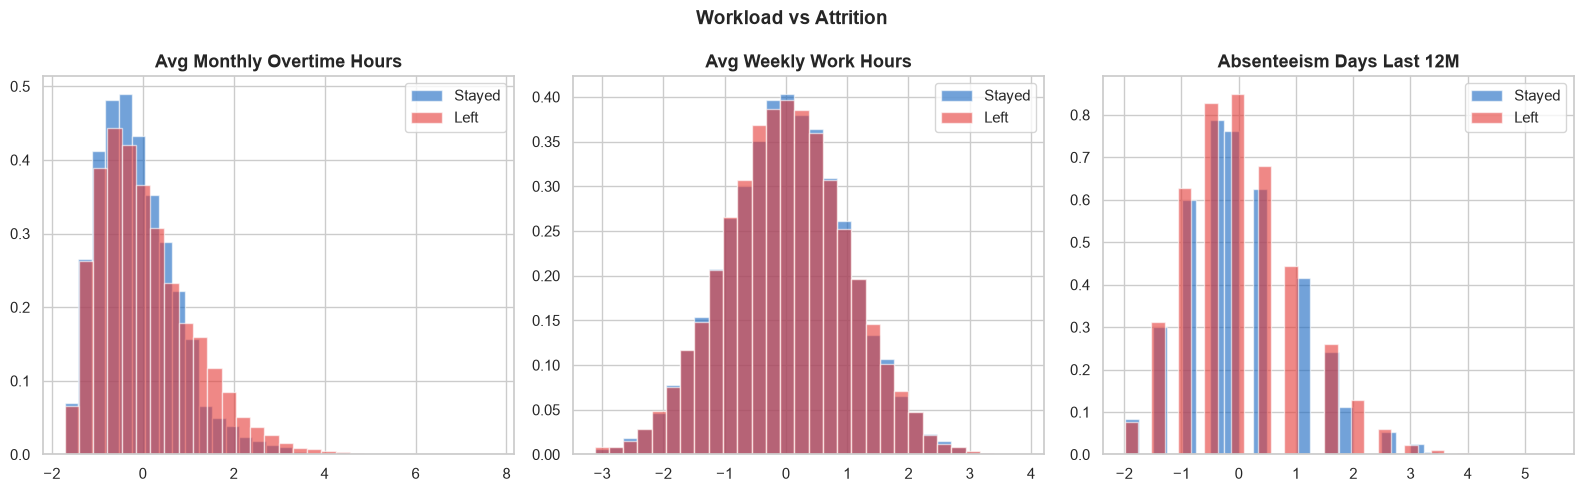

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, ['avg_monthly_overtime_hours', 'avg_weekly_work_hours', 'absenteeism_days_last_12m']):
    ax.hist(stayed[col], bins=30, alpha=0.6, color='#1565C0', label='Stayed', density=True)
    ax.hist(left[col],   bins=30, alpha=0.6, color='#E53935', label='Left',   density=True)
    ax.set_title(col.replace('_', ' ').title())
    ax.legend()

plt.suptitle('Workload vs Attrition', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/03_workload_attrition.png', dpi=150, bbox_inches='tight')
plt.show()


## 10. Correlation Matrix — All Features

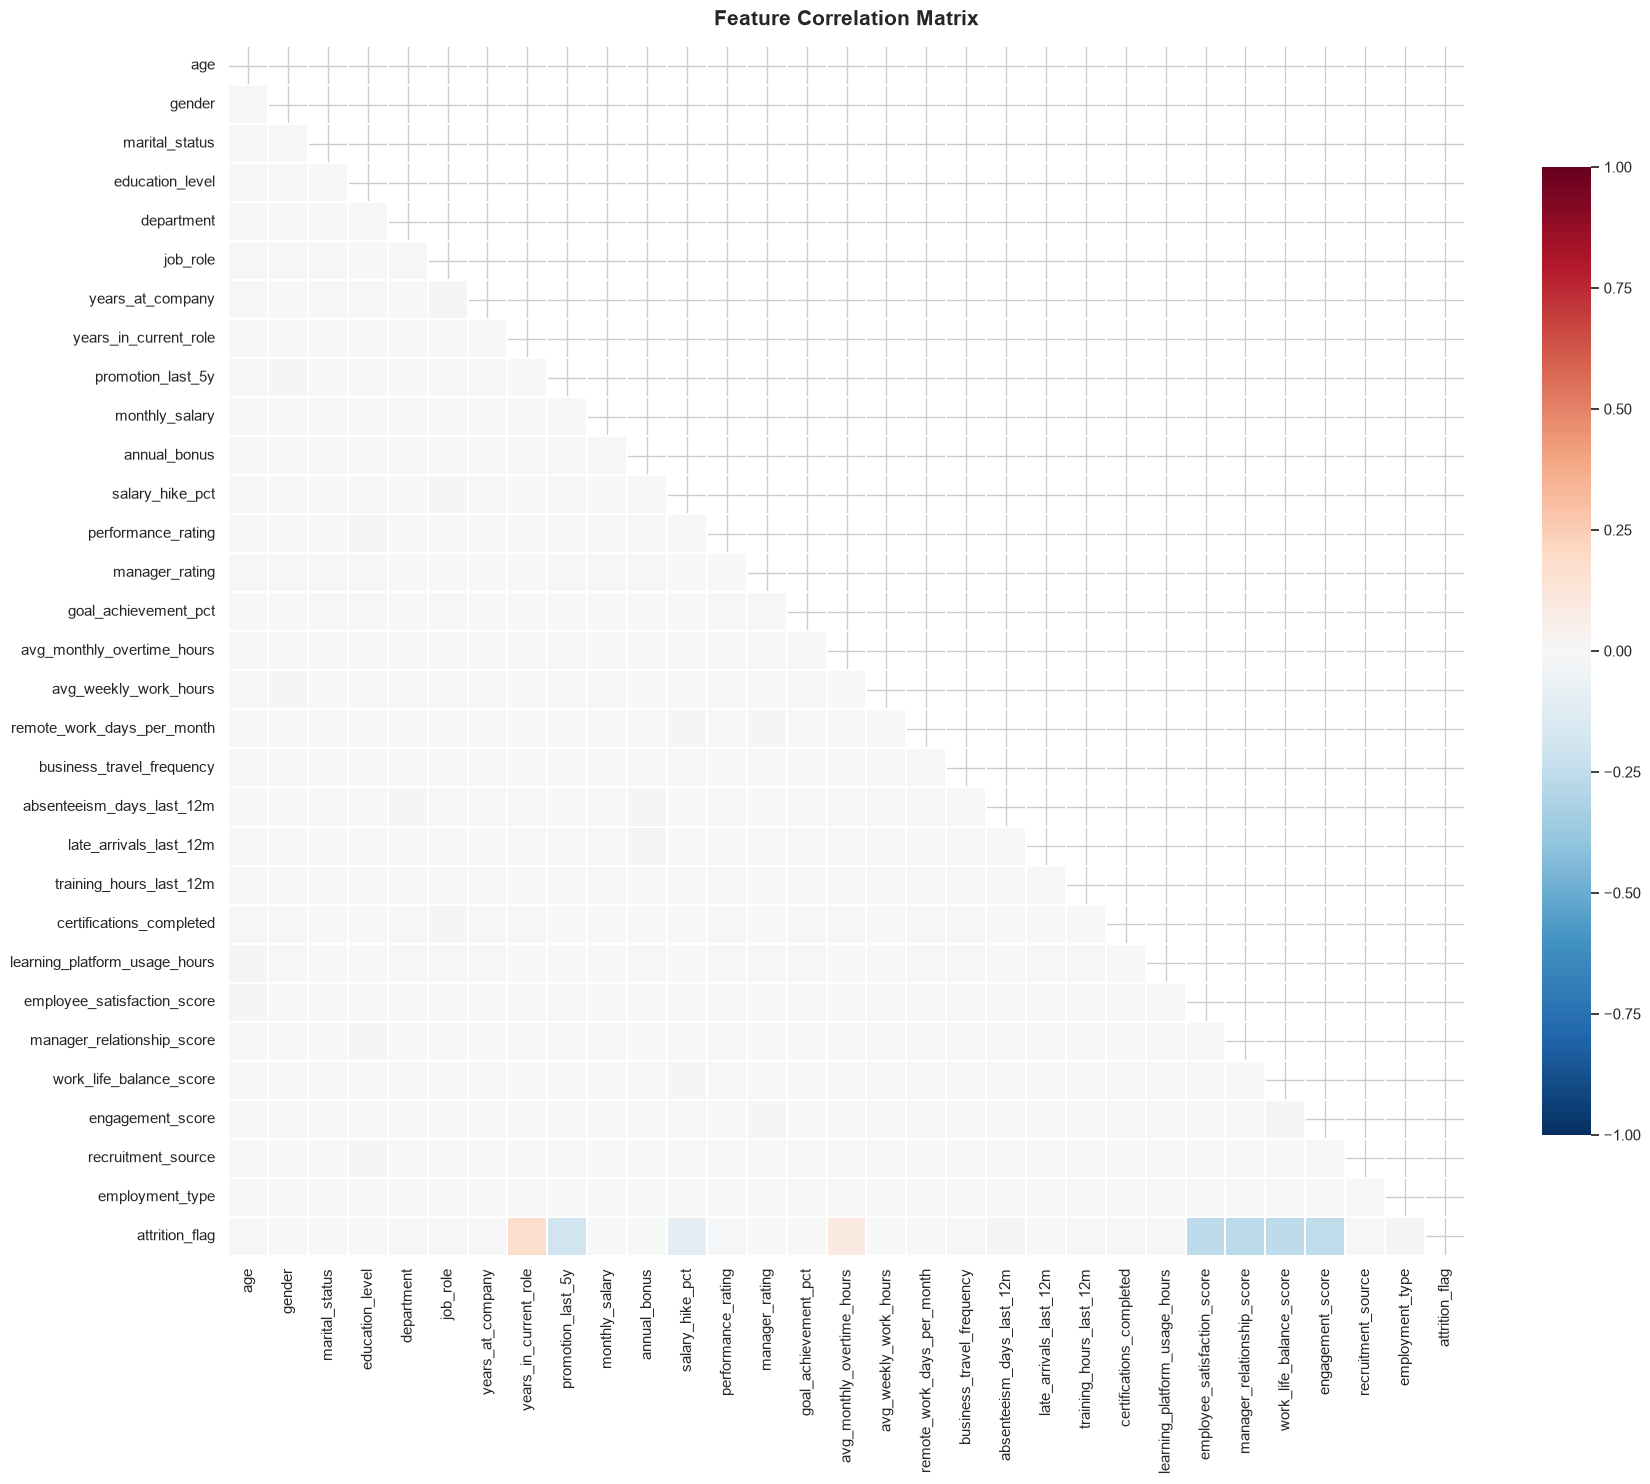

Saved full correlation heatmap.


In [10]:
plt.figure(figsize=(18, 15))
corr_matrix = df.corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=False, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.3, cbar_kws={"shrink": 0.8})
plt.title('Feature Correlation Matrix', fontsize=15, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('../reports/03_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved full correlation heatmap.")


## 11. Top Feature Correlations with Attrition

Top 15 features most correlated with attrition_flag:
manager_relationship_score     0.269
employee_satisfaction_score    0.264
work_life_balance_score        0.264
engagement_score               0.253
promotion_last_5y              0.200
years_in_current_role          0.172
salary_hike_pct                0.106
avg_monthly_overtime_hours     0.086
employment_type                0.010
absenteeism_days_last_12m      0.010
performance_rating             0.009
remote_work_days_per_month     0.007
years_at_company               0.007
certifications_completed       0.005
monthly_salary                 0.005


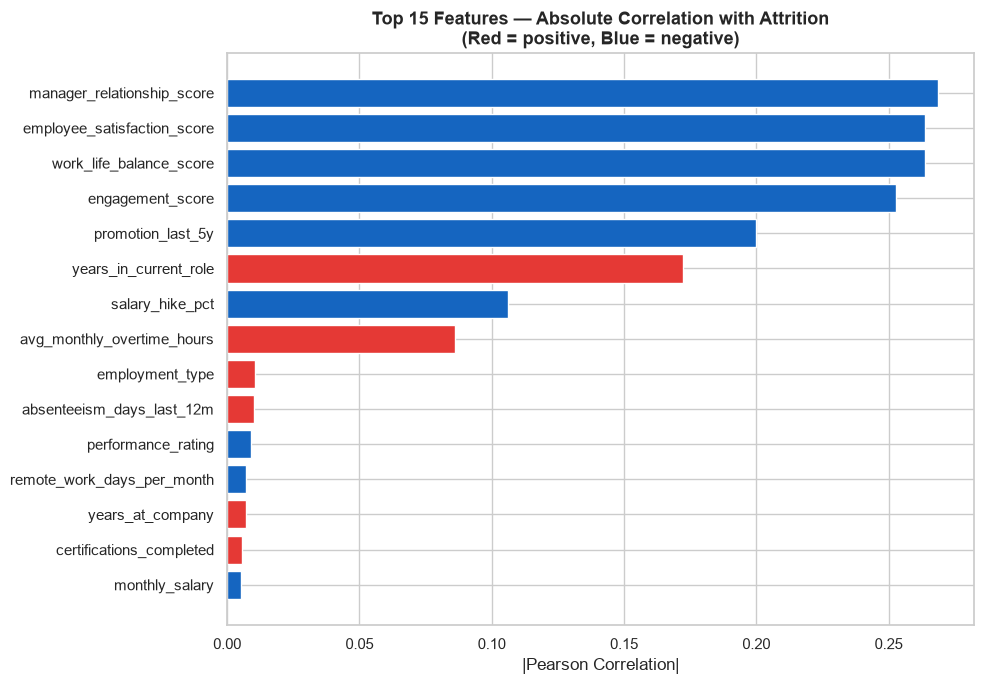

In [11]:
target_corr = df.corr()['attrition_flag'].drop('attrition_flag').abs().sort_values(ascending=False)

print("Top 15 features most correlated with attrition_flag:")
print(target_corr.head(15).round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 7))
top15 = target_corr.head(15)
colors = ['#E53935' if df.corr()['attrition_flag'][col] > 0 else '#1565C0' for col in top15.index]
ax.barh(top15.index[::-1], top15.values[::-1], color=colors[::-1], edgecolor='white')
ax.set_title('Top 15 Features — Absolute Correlation with Attrition\n(Red = positive, Blue = negative)',
             fontweight='bold')
ax.set_xlabel('|Pearson Correlation|')
plt.tight_layout()
plt.savefig('../reports/03_top_correlations.png', dpi=150, bbox_inches='tight')
plt.show()


## 12. Promotion & Travel vs Attrition

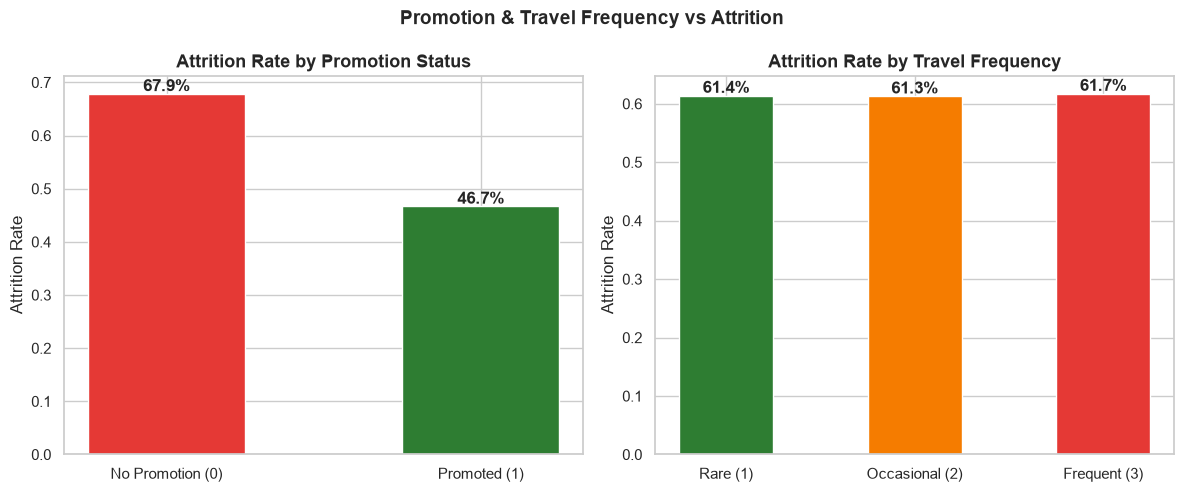

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


promo_attrition = df.groupby('promotion_last_5y')['attrition_flag'].mean()
axes[0].bar(['No Promotion (0)', 'Promoted (1)'], promo_attrition.values,
            color=['#E53935', '#2E7D32'], edgecolor='white', width=0.5)
axes[0].set_title('Attrition Rate by Promotion Status')
axes[0].set_ylabel('Attrition Rate')
for i, v in enumerate(promo_attrition.values):
    axes[0].text(i, v + 0.005, f'{v:.1%}', ha='center', fontweight='bold')


travel_attrition = df.groupby('business_travel_frequency')['attrition_flag'].mean()
axes[1].bar(['Rare (1)', 'Occasional (2)', 'Frequent (3)'], travel_attrition.values,
            color=['#2E7D32', '#F57C00', '#E53935'], edgecolor='white', width=0.5)
axes[1].set_title('Attrition Rate by Travel Frequency')
axes[1].set_ylabel('Attrition Rate')
for i, v in enumerate(travel_attrition.values):
    axes[1].text(i, v + 0.005, f'{v:.1%}', ha='center', fontweight='bold')

plt.suptitle('Promotion & Travel Frequency vs Attrition', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/03_promotion_travel.png', dpi=150, bbox_inches='tight')
plt.show()


## 13. EDA Summary — Key Findings

In [13]:
summary = [
    "=== EDA Key Findings ===",
    "",
    "DATASET:",
    "  - 50,500 employees | 31 features (after cleaning)",
    "  - 61.4% Left (majority), 38.6% Stayed (minority) -- class imbalance confirmed",
    "",
    "TOP ATTRITION DRIVERS (negative correlations = protective factors):",
    "  - Low manager_relationship_score  -> higher attrition risk",
    "  - Low employee_satisfaction_score -> higher attrition risk",
    "  - Low work_life_balance_score      -> higher attrition risk",
    "  - Low engagement_score             -> higher attrition risk",
    "  - No promotion in last 5 years     -> higher attrition risk",
    "",
    "COMPENSATION:",
    "  - Employees who left show lower monthly_salary distributions",
    "  - salary_hike_pct separation is moderate but visible",
    "",
    "WORKLOAD:",
    "  - Higher overtime hours linked to higher attrition",
    "  - Higher absenteeism_days also correlated with attrition",
    "",
    "TENURE:",
    "  - Shorter years_at_company      -> higher attrition (early-tenure risk)",
    "  - Shorter years_in_current_role -> higher attrition",
    "",
    "TRAVEL:",
    "  - Frequent travelers have higher attrition rate than Rare travelers",
    "",
    "IMPLICATIONS FOR FEATURE ENGINEERING (NB04):",
    "  - Create interaction feature: engagement_score x work_life_balance_score",
    "  - Create tenure bucket: early (under 2y), mid (2-5y), senior (5y+)",
    "  - Create compensation flag: salary below department median",
    "  - Consider log-transform on monthly_salary (long right tail)",
]
print("\n".join(summary))
print()
print("=== Notebook 03 Complete ===")
print("Proceed to: notebooks/04_feature_engineering.ipynb")


=== EDA Key Findings ===

DATASET:
  - 50,500 employees | 31 features (after cleaning)
  - 61.4% Left (majority), 38.6% Stayed (minority) -- class imbalance confirmed

TOP ATTRITION DRIVERS (negative correlations = protective factors):
  - Low manager_relationship_score  -> higher attrition risk
  - Low employee_satisfaction_score -> higher attrition risk
  - Low work_life_balance_score      -> higher attrition risk
  - Low engagement_score             -> higher attrition risk
  - No promotion in last 5 years     -> higher attrition risk

COMPENSATION:
  - Employees who left show lower monthly_salary distributions
  - salary_hike_pct separation is moderate but visible

WORKLOAD:
  - Higher overtime hours linked to higher attrition
  - Higher absenteeism_days also correlated with attrition

TENURE:
  - Shorter years_at_company      -> higher attrition (early-tenure risk)
  - Shorter years_in_current_role -> higher attrition

TRAVEL:
  - Frequent travelers have higher attrition rate than